# Estado del arte: ES semiparamétrica dinámica, retadores neuronales y el marco de backtest comparativo

- **Nivel:** 3, Estado del arte
- **Requisitos previos:** los cuadernos 04 y 05 de este tema (los backtests de ES y la comparación de modelos)
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este cuaderno puedes:

- nombrar los métodos académicos actuales para pronosticar VaR y ES conjuntamente, decir qué modela cada uno y cuáles de ellos corre la escalera y cuáles no;
- enunciar el marco de backtest comparativo: por qué un validador pregunta si un retador supera al campeón, y cómo responde Contraste;
- leer, desde seis ventanas de mercado versionadas, cómo se ordenan los escalones semiparamétricos dinámicos y CAViaR-ES frente a los clásicos, y contrastar algunas de esas diferencias con Diebold-Mariano;
- leer el registro de cuántas veces esos ajustes no convergieron, y decir qué implica eso para usarlos;
- ajustar el GARCH-t del producto sobre los retornos realizados versionados con el motor y con la referencia `arch`, y decir qué muestra y qué no muestra esa verificación;
- decir qué respalda y qué no respalda la evidencia, y qué queda por ejecutar.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2 arch==8.0.0 pandas==3.0.6
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import special, stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib", "arch", "pandas"):
    print(name, md.version(name))

# Los valores de luz del motor, con las palabras que imprime este cuaderno
LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada"}

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2
arch 8.0.0
pandas 3.0.6


## Datos

Los datos son el caso C11: el documento de la escalera `models-ladder.json` y los seis documentos de ventana. Para cada escalón y ventana guardan los pronósticos de VaR y ES, la pérdida FZ0 media y el número de reajustes y fallas de convergencia. Dos ventanas (`fx-2008`, `rates-2022`) versionan las pérdidas realizadas, así que las comparaciones de Diebold-Mariano del paso 2 se recalculan allí; las otras cuatro se leen de las filas versionadas.

Lo que este cuaderno **no puede** hacer, y lo dice. Los estimadores de este nivel (los modelos GAS-FZ y CAViaR) necesitan al menos 500 retornos para ajustarse, y ninguna ventana versiona sus retornos de estimación (solo derivados o 1.000 días fuera del archivo), así que no se reajustan aquí. El paquete `arch`, que el producto usa para su escalón GARCH y que sus propias pruebas usan como referencia, está instalado aquí, así que el paso 3 ajusta el GARCH-t sobre las dos series de retornos realizados que versionan las ventanas y compara el motor con una llamada directa a `arch`. Lo que sigue sin poder hacer es reproducir los pronósticos GARCH-t versionados: se ajustaron con 1.000 días de estimación que no están versionados. La evidencia de los rangos y las pruebas de los pasos 1 y 2 son entonces los pronósticos versionados, que el motor calculó y los artefactos registran.

In [2]:
# Cargar el documento de la escalera y las seis ventanas, y listar los escalones de los niveles del estado del arte con lo que la escalera registra de ellos
ROOT = Path("../../..").resolve()
NAMES = ("calm-2004-06", "equity-2007-09", "equity-2020", "rates-2022", "fx-2008", "mixed-2023")
docs = {w: json.loads((ROOT / "data" / "derived" / "C11" / f"{w}.json").read_text(encoding="utf-8")) for w in NAMES}
ladder = json.loads((ROOT / "data" / "derived" / "C11" / "models-ladder.json").read_text(encoding="utf-8"))["fit"]["ladder"]
print("calculado por riskvalidation", docs["fx-2008"]["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)
for entry in ladder:
    if entry["rung"] in ("R8", "R9", "R10"):
        print(f"{entry['model_id']:11s} {entry['rung']:4s} {entry['status']:20s} | {entry['source']}")
        print(f"{'':16s} {entry['title']['es']}")

calculado por riskvalidation 0.7.0 | instalado 0.8.1
caviar-sav  R8   fitted               | Engle and Manganelli 2004, JBES 22(4)
                 CAViaR, valor absoluto simetrico
caviar-as   R8   fitted               | Engle and Manganelli 2004, JBES 22(4)
                 CAViaR, pendiente asimetrica
caviar-es   R8   fitted               | Taylor 2019, JBES 37(1); two-step estimation declared in the engine (D-10)
                 ES-CAViaR (dos pasos, Taylor)
gas-fz-1    R9   fitted               | Patton, Ziegel and Chen 2019, J. Econometrics 211(2)
                 GAS-FZ, un factor
gas-fz-2    R9   fitted               | Patton, Ziegel and Chen 2019, J. Econometrics 211(2)
                 GAS-FZ, dos factores
gas-hybrid  R9   fitted               | Patton, Ziegel and Chen 2019, J. Econometrics 211(2), eq 27
                 GARCH-FZ hibrido
nn-fz       R10  challenger-not-run   | arXiv 2606.04576 (preprint; challenger only)
                 Red de cuantiles entrenada con FZ0 (re

## Método

### Paso 1: el marco de backtest comparativo

Un backtest tradicional pregunta si **el modelo** es aceptable: su hipótesis nula es que los pronósticos son correctos (cuadernos 03 y 04). Nolde y Ziegel (2017) señalan que un regulador o un validador suele preguntar otra cosa: ¿es el modelo interno al menos tan bueno como uno estándar? Eso es un **backtest comparativo**: ambos modelos se puntúan con una pérdida consistente, aquí FZ0, y la nula es que el primero no es peor que el segundo. Contraste aplica el marco en dos pasos (cuaderno 05): los backtests tradicionales deciden la elegibilidad, y la comparación por FZ0 media, Diebold-Mariano y el conjunto de confianza de modelos ordena a los elegibles.

Dentro de este marco la pregunta de este nivel es concreta: ¿los estimadores más nuevos, que modelan el VaR y la ES conjuntamente y los dejan evolucionar con los datos, se ubican sobre los escalones clásicos? La primera celda ordena, en cada ventana al 1 por ciento, los 14 escalones que pronostican una ES por su FZ0 media versionada (el rango 1 es la menor pérdida) e imprime el rango de los cuatro más nuevos: `caviar-es`, `gas-fz-1`, `gas-fz-2` y `gas-hybrid`. Los rangos son dentro de una ventana; los niveles de FZ0 no son comparables entre ventanas.

In [3]:
# Ordenar los 14 escalones con ES por FZ0 media versionada (1 es el mejor) en cada ventana al 1%, e imprimir el rango de los cuatro más nuevos
newest = ("caviar-es", "gas-fz-1", "gas-fz-2", "gas-hybrid")
print(f"{'ventana':15s} " + " ".join(f"{m:>10s}" for m in newest) + "   mejor escalón (FZ0)")
ranks = {}
for window in NAMES:
    scores = {}
    for model in docs[window]["outputs"]["models"]:
        level = model["by_level"][0]
        if level["fz0_mean"] is not None and level["n_fz0"] == level["n_scored"]:
            scores[model["model_id"]] = level["fz0_mean"]
    order = sorted(scores, key=scores.get)
    ranks[window] = {m: order.index(m) + 1 for m in order}
    best = order[0]
    print(f"{window:15s} " + " ".join(f"{ranks[window][m]:>7d}/{len(order)}" for m in newest) + f"   {best} ({scores[best]:.3f})")

ventana          caviar-es   gas-fz-1   gas-fz-2 gas-hybrid   mejor escalón (FZ0)
calm-2004-06          7/14      11/14      12/14      13/14   gjr-t (-4.521)
equity-2007-09        5/14      11/14      10/14      13/14   gjr-t (-2.876)
equity-2020           3/14       9/14      10/14       7/14   fhs (-1.986)
rates-2022            5/14      13/14      12/14      11/14   ewma (-3.811)
fx-2008               1/14      14/14      12/14      13/14   caviar-es (-3.557)
mixed-2023            7/14       9/14      11/14       8/14   gjr-t (-4.439)


### Paso 2: contrastar la diferencia, Diebold-Mariano frente a dos referencias clásicas

Un rango no es una prueba. Donde las pérdidas realizadas están versionadas podemos contrastar la diferencia de FZ0 media entre un escalón nuevo y una referencia clásica con `diebold_mariano` (pronósticos a un paso, sin rezagos, como en la comparación versionada). Las referencias son `ewma` (el modelo simple de volatilidad) y `evt-mf` (el escalón de EVT condicional); una diferencia media negativa significa que el escalón nuevo tiene la menor pérdida. La celda contrasta los cuatro escalones nuevos contra ambas referencias al 1 y al 2,5 por ciento en `fx-2008` y `rates-2022` e imprime la diferencia media, el estadístico y el valor p.

In [4]:
# Diebold-Mariano de los cuatro escalones más nuevos contra ewma y evt-mf sobre la pérdida FZ0, en las dos ventanas con pérdidas realizadas
from riskvalidation.market.scoring import diebold_mariano, fz0_loss

print(f"{'ventana':11s} {'alfa':>5s} {'escalón':10s} {'frente a':8s} {'dif. media':>10s} {'DM':>7s} {'p':>8s}  lectura")
for window in ("fx-2008", "rates-2022"):
    y = -np.array(docs[window]["outputs"]["grid"]["realised_loss"]["loss"])
    models = {m["model_id"]: m for m in docs[window]["outputs"]["models"]}
    for alpha in (0.01, 0.025):
        def loss_of(model_id):
            level = [lv for lv in models[model_id]["by_level"] if lv["alpha"] == alpha][0]
            return fz0_loss(y, -np.array(level["var"]), -np.array(level["es"]), alpha)
        for rung in newest:
            for reference in ("ewma", "evt-mf"):
                result = diebold_mariano(loss_of(rung), loss_of(reference), 0)
                reading = "indistinguible" if result.p_value >= 0.05 else ("nuevo mejor" if result.mean_diff < 0 else "nuevo peor")
                print(f"{window:11s} {alpha:5.3f} {rung:10s} {reference:8s} {result.mean_diff:10.4f} {result.statistic:7.2f} {result.p_value:8.4f}  {reading}")

ventana      alfa escalón    frente a dif. media      DM        p  lectura
fx-2008     0.010 caviar-es  ewma        -0.0691   -1.41   0.1580  indistinguible
fx-2008     0.010 caviar-es  evt-mf      -0.0475   -1.15   0.2498  indistinguible
fx-2008     0.010 gas-fz-1   ewma        15.3996    2.20   0.0276  nuevo peor
fx-2008     0.010 gas-fz-1   evt-mf      15.4212    2.20   0.0275  nuevo peor
fx-2008     0.010 gas-fz-2   ewma         5.0436    2.90   0.0037  nuevo peor
fx-2008     0.010 gas-fz-2   evt-mf       5.0652    2.89   0.0039  nuevo peor
fx-2008     0.010 gas-hybrid ewma        12.1888    2.37   0.0179  nuevo peor
fx-2008     0.010 gas-hybrid evt-mf      12.2104    2.37   0.0179  nuevo peor
fx-2008     0.025 caviar-es  ewma        -0.0024   -0.07   0.9438  indistinguible
fx-2008     0.025 caviar-es  evt-mf       0.0069    0.22   0.8292  indistinguible
fx-2008     0.025 gas-fz-1   ewma         0.0692    1.03   0.3025  indistinguible
fx-2008     0.025 gas-fz-1   evt-mf       0.078

### Paso 3: el ajuste GARCH-t del motor contra la referencia `arch`

El escalón GARCH del producto es un ajuste de cuasi máxima verosimilitud de un GARCH(1,1) con innovaciones t de Student y media constante, y el motor lo ejecuta a través del paquete `arch` (`riskvalidation.market.garch.fit_garch`). Eso tiene una consecuencia que conviene decir primero: `arch` es la referencia de las pruebas del propio motor y no una reimplementación independiente, así que esta verificación no puede encontrar un error dentro de `arch`. Verifica lo que el motor agrega alrededor de la llamada: el escalamiento de los retornos a porcentaje y de vuelta a decimales, el desplazamiento de la log-verosimilitud en $n \ln 100$, los nombres de los parámetros y el veredicto de convergencia. La celda ajusta los mismos retornos versionados de tres maneras: con el motor; con una llamada directa a `arch.arch_model` en porcentaje, cuyos parámetros se llevan de vuelta a decimales en la celda; y con `arch` otra vez desde un punto de partida distinto, lo que prueba que el óptimo pertenece a la verosimilitud y no al inicio.

Las entradas son las series de pérdida realizada que dos ventanas versionan (un retorno es la pérdida con el signo cambiado): 251 días en `fx-2008` y 249 en `rates-2022`. El motor necesita al menos 250 retornos para ajustar, así que `rates-2022` queda fuera de lo que acepta: la celda muestra el rechazo y ajusta solo `arch`, sin comparación. Las tolerancias se fijan antes de la ejecución. Motor contra la llamada directa a `arch`: diferencia relativa menor que $10^{-9}$ (mismo optimizador y mismo inicio, así que solo puede diferir el orden de las operaciones de coma flotante). `arch` desde el segundo inicio: log-verosimilitud dentro de $10^{-6}$ y parámetros dentro de $10^{-3}$ relativo (el optimizador se detiene en una tolerancia, y la verosimilitud GARCH es plana cerca de su óptimo).

In [5]:
# Ajustar el GARCH-t del motor y la referencia arch sobre los retornos realizados versionados de las dos ventanas que versionan una serie de pérdidas
import warnings

import arch
from riskvalidation.market import garch

PARAMS = ("mu", "omega", "alpha[1]", "beta[1]", "nu")


def arch_fit(returns, start=None):
    """La llamada de referencia: retornos en porcentaje, GARCH(1,1), media constante, t de Student; mu y omega se llevan aquí de vuelta a decimales."""
    model = arch.arch_model(returns * 100, mean="Constant", vol="GARCH", p=1, q=1, dist="t", rescale=False)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        res = model.fit(disp="off", show_warning=False, update_freq=0, starting_values=start)
    p = res.params
    decimals = {"mu": p["mu"] / 100, "omega": p["omega"] / 100**2, "alpha[1]": p["alpha[1]"], "beta[1]": p["beta[1]"], "nu": p["nu"]}
    return decimals, res.loglikelihood + len(returns) * math.log(100), res.convergence_flag


SECOND_START = np.array([0.0, 0.05, 0.10, 0.80, 8.0])  # mu, omega, alpha, beta, nu, en unidades de porcentaje, fijado de antemano
TOL_SAME, TOL_LL, TOL_START = 1e-9, 1e-6, 1e-3
for window in ("fx-2008", "rates-2022"):
    loss = docs[window]["outputs"]["grid"]["realised_loss"]["loss"]
    returns = -np.array(loss)
    print(f"{window}: {returns.size} retornos realizados versionados")
    reference, reference_ll, flag = arch_fit(returns)
    try:
        fit = garch.fit_garch(returns, "garch", "student-t", "constant")
    except ValueError:
        print(f"  el motor rechaza esta serie: necesita al menos {garch.MIN_OBS} retornos y hay {returns.size}")
        print("  arch solo, sin comparación:", {k: round(float(v), 6) for k, v in reference.items()}, "| log-verosimilitud", round(float(reference_ll), 3))
        continue
    second, second_ll, second_flag = arch_fit(returns, SECOND_START)
    print(f"  {'parámetro':10s} {'motor':>14s} {'arch':>14s} {'dif. relativa':>14s} {'arch, 2.º inicio':>16s}")
    worst_same = worst_start = 0.0
    for name in PARAMS:
        rel_same = abs(fit.params[name] - reference[name]) / abs(reference[name])
        rel_start = abs(second[name] - reference[name]) / abs(reference[name])
        worst_same, worst_start = max(worst_same, rel_same), max(worst_start, rel_start)
        print(f"  {name:10s} {fit.params[name]:14.8g} {reference[name]:14.8g} {rel_same:14.2e} {second[name]:16.8g}")
    print(f"  log-verosimilitud: motor {fit.log_likelihood:.6f} | arch {reference_ll:.6f} | arch, 2.º inicio {second_ll:.6f}")
    print(f"  el motor convergió {'sí' if fit.converged else 'no'} | indicador de arch {flag} | indicador de arch, 2.º inicio {second_flag}")
    print(f"  motor contra arch: mayor diferencia relativa {worst_same:.2e}, tolerancia {TOL_SAME:.0e}, dentro: {'sí' if worst_same < TOL_SAME else 'no'}")
    print(f"  segundo inicio: diferencia de log-verosimilitud {abs(second_ll - reference_ll):.2e} (tolerancia {TOL_LL:.0e}), mayor diferencia relativa de parámetros {worst_start:.2e} (tolerancia {TOL_START:.0e}), dentro: {'sí' if abs(second_ll - reference_ll) < TOL_LL and worst_start < TOL_START else 'no'}")


fx-2008: 251 retornos realizados versionados
  parámetro           motor           arch  dif. relativa arch, 2.º inicio
  mu         -0.00075822796 -0.00075822796       0.00e+00   -0.00075814964
  omega       1.8944118e-06  1.8944118e-06       0.00e+00     1.894279e-06
  alpha[1]      0.044303998    0.044303998       0.00e+00        0.0443091
  beta[1]        0.94373067     0.94373067       0.00e+00       0.94372384
  nu              5.2144163      5.2144163       0.00e+00        5.2142774
  log-verosimilitud: motor 803.654204 | arch 803.654204 | arch, 2.º inicio 803.654203
  el motor convergió sí | indicador de arch 0 | indicador de arch, 2.º inicio 0
  motor contra arch: mayor diferencia relativa 0.00e+00, tolerancia 1e-09, dentro: sí
  segundo inicio: diferencia de log-verosimilitud 8.26e-08 (tolerancia 1e-06), mayor diferencia relativa de parámetros 1.15e-04 (tolerancia 1e-03), dentro: sí
rates-2022: 249 retornos realizados versionados
  el motor rechaza esta serie: necesita al men

## Estado del arte

Los métodos de abajo son la frontera académica actual para pronosticar VaR y ES conjuntamente, con su situación en la escalera.

| Método | Qué modela | En la escalera | Fuente |
|---|---|---|---|
| **GAS-FZ, un factor** | el VaR y la ES como $v_t = a\,e^{\kappa_t}$, $e_t = b\,e^{\kappa_t}$ con $\kappa_{t+1} = \beta\kappa_t + \gamma\,(-1/e_t)\big(\tfrac1\alpha \mathbb 1\{y_t \le v_t\}y_t - e_t\big)$, estimado minimizando la pérdida FZ0 promedio | `gas-fz-1`, escalón R9 | Patton, Ziegel y Chen (2019) |
| **GAS-FZ, dos factores** | $(v, e)_{t+1} = w + B\,(v, e)_t + A\,(\lambda_v, \lambda_e)_t$, una recursión impulsada por el score con un factor propio por medida | `gas-fz-2`, escalón R9 | Patton, Ziegel y Chen (2019) |
| **GARCH-FZ híbrido** | el modelo de un factor más un término $\delta\ln\lvert y_t\rvert$ agregado a la recursión del factor | `gas-hybrid`, escalón R9 | Patton, Ziegel y Chen (2019), ecuación 27 |
| **CAViaR-ES** | el VaR sigue una recursión CAViaR; la ES es el VaR menos una brecha autorregresiva, por verosimilitud Laplace asimétrica | `caviar-es`, escalón R8, estimado en **dos pasos** (el motor declara esto como su desviación respecto de la estimación conjunta de Taylor) | Taylor (2019) |
| **Modelos de cuantiles y de cuantiles neuronales sobre la pérdida FZ** | cuantiles de retorno y ES desde una red entrenada con FZ0; una línea activa de preprints | `nn-fz`, escalón R10, **no ejecutado** | preprints recientes (por ejemplo arXiv 2606.04576) |
| **Backtest comparativo** | el marco del paso 1: H0 es que el modelo interno no es peor que uno estándar, bajo una pérdida consistente | la comparación del cuaderno 05 | Nolde y Ziegel (2017) |
| **Backtests multinomiales de VaR** | varios niveles de VaR a la vez como un backtest implícito de ES | **no está en el motor** | Kratz, Lok y McNeil (2018) |

La situación honesta de la línea neuronal, a la fecha de la investigación detrás de este producto, es que ningún regulador la reconoce como estándar para modelos internos y sus ganancias sobre un referente GARCH, EVT o GAS-FZ bien especificado dependen del conjunto de datos. Contraste la trata por eso solo como retador: tendría que entrar al conjunto de confianza de 90 por ciento en FZ0 **fuera de muestra**, mostrado por Diebold-Mariano y el conjunto de confianza y no por ajuste dentro de muestra. El documento de la escalera registra que `nn-fz` no se entrenó; nada en los datos versionados evalúa un modelo neuronal, y este cuaderno no afirma que uno lo haría mejor o peor.

La celda imprime el registro versionado de cómo se comportaron los ajustes más nuevos: la proporción de reajustes que no convergieron, por escalón y ventana.

In [6]:
# La proporción versionada de reajustes que no convergieron, por escalón y ventana, para los escalones más nuevos y dos referencias clásicas
fits = {entry["model_id"]: {wf["window_id"]: wf for wf in entry["window_fits"]} for entry in ladder if entry["window_fits"]}
print(f"{'escalón':11s}" + "".join(f"{w[:12]:>14s}" for w in NAMES) + f"{'todas':>14s}")
for model_id in ("garch-t", "caviar-es", "gas-fz-1", "gas-fz-2", "gas-hybrid"):
    shares = [fits[model_id][w]["n_convergence_failures"] / fits[model_id][w]["n_refits"] for w in NAMES]
    total = sum(fits[model_id][w]["n_convergence_failures"] for w in NAMES) / sum(fits[model_id][w]["n_refits"] for w in NAMES)
    print(f"{model_id:11s}" + "".join(f"{s:14.1%}" for s in shares) + f"{total:14.1%}")

escalón      calm-2004-06  equity-2007-   equity-2020    rates-2022       fx-2008    mixed-2023         todas
garch-t              0.0%         20.8%          0.0%          0.0%         39.8%         79.7%         13.3%
caviar-es            0.0%          0.5%          0.0%          0.0%          0.0%          0.0%          0.1%
gas-fz-1             0.0%          0.0%         16.7%          3.8%         14.8%          0.0%          3.5%
gas-fz-2            48.9%         43.3%         35.7%         60.7%         48.3%         25.0%         47.2%
gas-hybrid           7.9%          7.7%          8.3%          7.7%         29.6%          0.0%         10.4%


La última celda dibuja los rangos del paso 1: para cada ventana el rango de los cuatro escalones más nuevos entre los 14 con ES, con el veredicto de elegibilidad versionado marcado. Un rango bajo de un modelo inelegible no es un campeón (cuaderno 05), y la figura muestra dónde difieren.

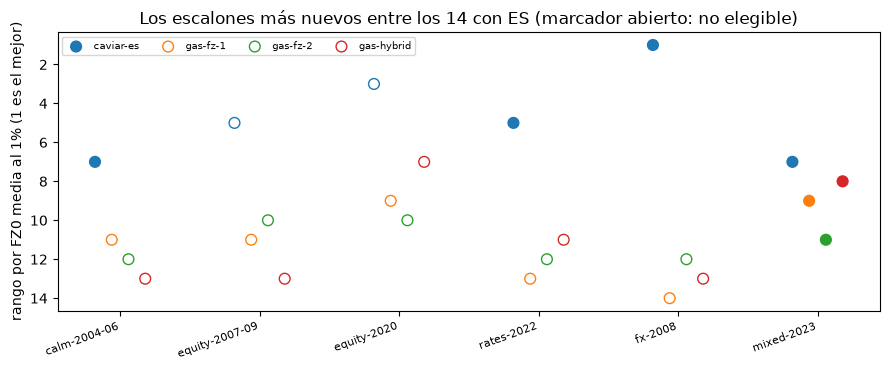

In [7]:
# Dibujar el rango de cada escalón nuevo en cada ventana (1 es el mejor); un marcador lleno es un modelo elegible, uno abierto no lo es
fig, ax = plt.subplots(figsize=(9, 3.8))
for offset, rung in enumerate(newest):
    xs = np.arange(len(NAMES)) + (offset - 1.5) * 0.12
    ys = [ranks[w][rung] for w in NAMES]
    eligible = [[m for m in docs[w]["outputs"]["models"] if m["model_id"] == rung][0]["eligible"] for w in NAMES]
    ax.scatter(xs, ys, s=60, label=rung, facecolors=["none" if not e else f"C{offset}" for e in eligible], edgecolors=f"C{offset}")
ax.invert_yaxis()
ax.set_xticks(range(len(NAMES)))
ax.set_xticklabels(NAMES, rotation=20, ha="right", fontsize=8)
ax.set_ylabel("rango por FZ0 media al 1% (1 es el mejor)")
ax.set_title("Los escalones más nuevos entre los 14 con ES (marcador abierto: no elegible)")
ax.legend(fontsize=7, ncol=4)
fig.tight_layout()
plt.show()

## Resultados

- **Rangos.** Entre los 14 escalones con ES, al 1 por ciento, `caviar-es` ocupa los lugares 7, 5, 3, 5, 1 y 7 en las seis ventanas (primero en `fx-2008`, donde es el campeón); `gas-fz-1` 11, 11, 9, 13, 14 y 9; `gas-fz-2` 12, 10, 10, 12, 12 y 11; `gas-hybrid` 13, 13, 7, 11, 13 y 8. El mejor escalón es `gjr-t` en tres ventanas, `fhs` en `equity-2020`, `ewma` en `rates-2022` y `caviar-es` en `fx-2008`. Ningún escalón GAS-FZ está entre los seis primeros lugares de alguna ventana.
- **Las pruebas coinciden con los rangos.** `caviar-es` es indistinguible de `ewma` y de `evt-mf` en las 8 comparaciones (dos ventanas, dos niveles, dos referencias, con FZ0 como pérdida). Las 24 comparaciones de los tres escalones GAS-FZ contra las dos referencias tienen siempre una diferencia media positiva, es decir, el escalón nuevo tiene la pérdida mayor; 12 de las 24 son significativas al 5 por ciento, ninguna en la dirección contraria. En `fx-2008` al 1 por ciento los tres son significativamente peores que ambas referencias (diferencias medias de 15,4, 5,0 y 12,2 para `gas-fz-1`, `gas-fz-2` y `gas-hybrid` frente a `ewma`), lo que es una falla de la recursión ajustada, no una pérdida pequeña.
- **Cómo se comportaron los ajustes.** En las seis ventanas 47,2 por ciento de los reajustes de `gas-fz-2` no convergió, 10,4 por ciento de `gas-hybrid`, 3,5 por ciento de `gas-fz-1` y 0,1 por ciento de `caviar-es`. Como comparación, GARCH-t no convergió en 13,3 por ciento, concentrado en `mixed-2023` (79,7 por ciento, 51 de 64) y `fx-2008` (39,8 por ciento). El registro no dice cómo trató el pipeline un reajuste fallido; dice solo que el modelo de dos factores es el menos confiable de ajustar.
- **Qué respalda la evidencia.** En estas ventanas, con los ajustes de estimación del producto (reajustes diarios para la familia GARCH, cinco días para CAViaR, veinte para GAS-FZ, 20 partidas), los escalones semiparamétricos dinámicos no superaron a los clásicos, y el escalón CAViaR-ES los igualó. La evidencia son los pronósticos versionados de seis ventanas, en dos niveles, con los tamaños de muestra que tienen las ventanas (64 a 750 días); no respalda una afirmación sobre esos métodos en general, y calla sobre un modelo neuronal, que no se ejecutó.
- **El ajuste GARCH-t contra `arch`.** Sobre los 251 retornos realizados versionados de `fx-2008`, el `fit_garch` del motor y una llamada directa a `arch` devuelven los mismos cinco parámetros (mayor diferencia relativa 0, tolerancia 1e-9) y la misma log-verosimilitud, 803,654204; el motor informa convergencia y `arch` devuelve el indicador 0. `arch` desde un segundo punto de partida llega a una log-verosimilitud a 8,3e-08 de distancia y a parámetros dentro de 1,15e-04 relativo, dentro de las tolerancias fijadas. El motor llama a `arch`, así que esto confirma su envoltura (el escalamiento a porcentaje y de vuelta, el desplazamiento de la log-verosimilitud, los nombres de los parámetros) y que el óptimo no depende del inicio; no prueba a `arch` mismo. `rates-2022` versiona 249 retornos, uno menos que el mínimo de 250 del motor: el motor lo rechaza, y `arch` solo lo ajusta (beta 0,978, nu 18,5, alpha en el borde 0), sin nada que comparar.
- **Qué no se ejecuta aquí.** Los estimadores GAS-FZ y CAViaR no se reajustaron (no hay retornos de estimación versionados, se necesitan al menos 500), y los pronósticos GARCH-t versionados no se reprodujeron: se ajustaron con 1.000 días de estimación que no están versionados, y los retornos versionados de `fx-2008` son su ventana de pronóstico, no esa muestra de estimación.

Lo que este cuaderno no muestra: ningún componente nuevo de Contraste más allá de esta práctica; esos están en los cuadernos de nivel 4 de los temas que llevan una afirmación.

## Resumen

- Los métodos más nuevos para VaR y ES modelan el par conjuntamente y lo dejan evolucionar con los datos: GAS-FZ y su híbrido minimizan la propia pérdida FZ0, CAViaR-ES agrega una ES a una recursión de cuantil, y los modelos de cuantiles neuronales son una línea de preprints.
- El marco de backtest comparativo pregunta si un retador supera a un modelo estándar bajo una pérdida consistente, no solo si el campeón es rechazado; Contraste lo usa después de que los backtests tradicionales han decidido la elegibilidad.
- En seis ventanas de mercado versionadas los escalones más nuevos no se ubican de forma consistente sobre los clásicos, y los escalones GAS-FZ son los menos estables en el registro de sus ajustes.
- El retador neuronal se registra como no ejecutado, así que la escalera no ofrece evidencia sobre él; tendría que entrar al conjunto de confianza de 90 por ciento fuera de muestra.
- El ajuste GARCH-t del motor es igual a una llamada directa a `arch` sobre los retornos versionados de `fx-2008` hasta los dígitos impresos y no depende del inicio del optimizador; eso verifica la envoltura del motor, no a `arch`.
- Los reajustes de los estimadores más nuevos y los pronósticos GARCH-t versionados no se reproducen aquí, por falta de retornos de estimación versionados; la evidencia de los rangos son los pronósticos versionados.

**Qué probar después.** Recalcula la tabla del paso 2 en el otro nivel de `rates-2022` y nombra la ventana y el nivel en que un escalón nuevo es significativamente mejor que una referencia, si lo hay; luego lee la página del caso de C11 para la escalera completa.

## Referencias

- Patton, A. J., Ziegel, J. F. y Chen, R. (2019), Dynamic semiparametric models for expected shortfall (and value-at-risk), Journal of Econometrics 211(2). https://doi.org/10.1016/j.jeconom.2018.10.008 (preprint https://arxiv.org/abs/1707.05108)
- Taylor, J. W. (2019), Forecasting value at risk and expected shortfall using a semiparametric approach based on the asymmetric Laplace distribution, Journal of Business and Economic Statistics 37(1). https://doi.org/10.1080/07350015.2017.1281815
- Nolde, N. y Ziegel, J. F. (2017), Elicitability and backtesting: perspectives for banking regulation, Annals of Applied Statistics 11(4). https://doi.org/10.1214/17-AOAS1041
- Kratz, M., Lok, Y. H. y McNeil, A. J. (2018), Multinomial VaR backtests: a simple implicit approach to backtesting expected shortfall, Journal of Banking and Finance 88. https://doi.org/10.1016/j.jbankfin.2018.01.002
- Diebold, F. X. y Mariano, R. S. (1995), Comparing predictive accuracy, Journal of Business and Economic Statistics 13(3). https://doi.org/10.1080/07350015.1995.10524599
- Hansen, P. R., Lunde, A. y Nason, J. M. (2011), The model confidence set, Econometrica 79(2). https://doi.org/10.3982/ECTA5771
- Una red neuronal conjunta de VaR y ES entrenada con la pérdida FZ (preprint, solo retador). https://arxiv.org/abs/2606.04576